# EC5203 - Member 1: Dataset Audit and EDA

In [1]:
# STEP 0: Verify the Python environment

import sys

print("Active Python:", sys.executable)
print("Python version:", sys.version.split()[0])

Active Python: D:\chronic-disease-ml\.venv\Scripts\python.exe
Python version: 3.12.3


In [2]:
# STEP 1: Locate the group dataset

from pathlib import Path
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

csv_path = root / "data" / "raw" / "Data Warehouse Multiclass.csv"

assert csv_path.is_file(), f"Dataset not found: {csv_path}"

print("Project folder:", root)
print("Dataset found:", csv_path.name)
print("Dataset size:", round(csv_path.stat().st_size / (1024**2), 2), "MB")

Project folder: D:\chronic-disease-ml
Dataset found: Data Warehouse Multiclass.csv
Dataset size: 89.75 MB


In [3]:
# STEP 2: Load the group dataset

df = pd.read_csv(csv_path, low_memory=False)

print("Dataset loaded successfully!")
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nFirst 5 records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!
Total rows: 280985
Total columns: 39

First 5 records:


,composite_key,age_level,gender,bmi_level,smoking,diabetes,age,age_normalized,bmi,hypertension,...,salt_intake,heart_rate,hdl,ldl,education_level,employment_status,source_dataset,disease_flags,sublabel,label
0,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,9,0.080460,19.20,0.0,...,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal
1,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,3,0.011494,22.55,0.0,...,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal
2,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,3,0.011494,22.89,0.0,...,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal
3,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,3,0.011494,23.12,0.0,...,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal
4,Young_Female_Normal_Never_No,Young,Female,Normal,Never,No,4,0.022989,19.61,0.0,...,8.685304,74.329073,65.651757,129.220447,Primary,Retired,diabetes,"0,0,0",N,Normal



Column names:
['composite_key', 'age_level', 'gender', 'bmi_level', 'smoking', 'diabetes', 'age', 'age_normalized', 'bmi', 'hypertension', 'heart_disease', 'HbA1c_level', 'glucose', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'blood_pressure', 'high_blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'education_level', 'employment_status', 'source_dataset', 'disease_flags', 'sublabel', 'label']


In [4]:
# STEP 3: Identify target variable and disease classes

target = "sublabel"

print("Target variable:", target)
print("Number of disease classes:", df[target].nunique())

print("\nDisease class counts:")
class_counts = df[target].value_counts(dropna=False)
print(class_counts.to_string())

print("\nDisease class percentages:")
class_percentages = (
    df[target].value_counts(normalize=True, dropna=False) * 100
)
print(class_percentages.round(2).to_string())

print("\nRelationship between target and binary label:")
display(pd.crosstab(df["sublabel"], df["label"]))

print("\nExample disease labels:")
display(df[["sublabel", "label", "disease_flags"]].head(10))

Target variable: sublabel
Number of disease classes: 8

Disease class counts:
sublabel
N           106884
HY           69806
DI_HY        66473
DI           31918
HT            2595
DI_HT         1398
HT_HY         1066
DI_HT_HY       845

Disease class percentages:
sublabel
N           38.04
HY          24.84
DI_HY       23.66
DI          11.36
HT           0.92
DI_HT        0.50
HT_HY        0.38
DI_HT_HY     0.30

Relationship between target and binary label:


label,Abnormal,Normal
sublabel,,
DI,31918,0
DI_HT,1398,0
DI_HT_HY,845,0
DI_HY,66473,0
HT,2595,0
HT_HY,1066,0
HY,69806,0
N,0,106884



Example disease labels:


,sublabel,label,disease_flags
0,N,Normal,"0,0,0"
1,N,Normal,"0,0,0"
2,N,Normal,"0,0,0"
3,N,Normal,"0,0,0"
4,N,Normal,"0,0,0"
5,N,Normal,"0,0,0"
6,N,Normal,"0,0,0"
7,N,Normal,"0,0,0"
8,N,Normal,"0,0,0"
9,N,Normal,"0,0,0"


In [5]:
# STEP 4: Dataset Quality Audit
# This code only checks data. It does not modify the dataset.

print("=== DATA QUALITY AUDIT ===")

# 1. Dataset dimensions
print("\nTotal records:", df.shape[0])
print("Total columns:", df.shape[1])

# 2. Missing values
missing_values = df.isna().sum()

print("\nTotal missing values:", missing_values.sum())
print("\nColumns with missing values:")
print(missing_values[missing_values > 0].to_string())

# 3. Exact duplicate rows
duplicate_count = df.duplicated().sum()

print("\nExact duplicate rows:", duplicate_count)
print(
    "Duplicate percentage:",
    round(duplicate_count / len(df) * 100, 2),
    "%"
)

# 4. Constant columns
constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) == 1
]

print("\nConstant columns:", constant_columns)

# 5. Composite key uniqueness
print(
    "\nUnique composite_key values:",
    df["composite_key"].nunique()
)

print(
    "Repeated composite_key values:",
    df["composite_key"].duplicated().sum()
)

print("\nAudit completed. Original dataset unchanged.")

=== DATA QUALITY AUDIT ===

Total records: 280985
Total columns: 39

Total missing values: 0

Columns with missing values:
Series([], )



Exact duplicate rows: 2284
Duplicate percentage: 0.81 %



Constant columns: []

Unique composite_key values: 192
Repeated composite_key values: 280793

Audit completed. Original dataset unchanged.


In [6]:
# STEP 5: Numerical Data-Quality Inspection

import numpy as np

numeric_cols = df.select_dtypes(include="number").columns.tolist()

print("Total numerical columns:", len(numeric_cols))

numeric_audit = pd.DataFrame({
    "Minimum": df[numeric_cols].min(),
    "Maximum": df[numeric_cols].max(),
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Std_Dev": df[numeric_cols].std(),
    "Zero_Count": (df[numeric_cols] == 0).sum(),
    "Negative_Count": (df[numeric_cols] < 0).sum(),
    "Missing_Count": df[numeric_cols].isna().sum()
}).round(3)

display(numeric_audit)

# Check measurements that should not be negative
nonnegative_cols = [
    "age", "bmi", "glucose", "HbA1c_level",
    "cholesterol", "systolic_bp", "diastolic_bp"
]

print("\n=== NON-POSITIVE MEASUREMENT COUNTS ===")

for col in nonnegative_cols:
    if col in df.columns:
        print(col, ":", int((df[col] <= 0).sum()))

# Investigate columns described as binary indicators
print("\n=== SUSPECTED BINARY INDICATOR ISSUES ===")

for col in ["hypertension", "heart_disease"]:
    if col in df.columns:
        invalid = df[col].notna() & ~df[col].isin([0, 1])
        print(f"{col}: {invalid.sum()} values outside 0 and 1")
        print("Examples:", df.loc[invalid, col].head().tolist())

print("\nStep 5 completed. No data modified.")

Total numerical columns: 20


,Minimum,Maximum,Mean,Median,Std_Dev,Zero_Count,Negative_Count,Missing_Count
age,2.000,89.000,49.666,50.000,21.682,0,0,0
age_normalized,0.000,1.000,0.548,0.552,0.249,1195,0,0
bmi,10.010,95.690,27.491,27.320,7.040,0,0,0
hypertension,0.000,1.000,0.128,0.071,0.187,106307,0,0
heart_disease,0.000,1.000,0.073,0.007,0.138,121656,0,0
HbA1c_level,3.500,9.000,5.947,5.800,0.954,0,0,0
glucose,70.000,300.000,135.259,138.000,38.478,0,0,0
cholesterol,150.000,300.000,224.046,225.000,35.526,0,0,0
sleep_hours,4.000,10.000,6.955,6.975,1.426,0,0,0
triglycerides,50.000,400.000,178.996,179.000,67.336,0,0,0



=== NON-POSITIVE MEASUREMENT COUNTS ===
age : 0
bmi : 0
glucose : 0
HbA1c_level : 0
cholesterol : 0
systolic_bp : 0
diastolic_bp : 0

=== SUSPECTED BINARY INDICATOR ISSUES ===
hypertension: 166597 values outside 0 and 1
Examples: [0.08300395256917, 0.27734375, 0.0821880153930731, 0.010752688172043, 0.366666666666667]
heart_disease: 155406 values outside 0 and 1
Examples: [0.0553359683794466, 0.16796875, 0.0568993952721275, 0.003584229390681, 0.233333333333333]

Step 5 completed. No data modified.


In [7]:
# STEP 6: Categorical and Target Leakage Audit

categorical_cols = df.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Total categorical columns:", len(categorical_cols))
print("\nCategorical column names:")
print(categorical_cols)

category_summary = pd.DataFrame({
    "Column": categorical_cols,
    "Unique_Values": [
        df[col].nunique(dropna=False)
        for col in categorical_cols
    ],
    "Missing_Count": [
        df[col].isna().sum()
        for col in categorical_cols
    ]
})

display(category_summary)

print("\n=== SELECTED CATEGORICAL FREQUENCIES ===")

for col in [
    "gender", "smoking", "diabetes",
    "physical_activity", "source_dataset",
    "label", "sublabel", "disease_flags"
]:
    if col in df.columns:
        print(f"\n{col}")
        print(df[col].value_counts(dropna=False).head(15).to_string())

print("\n=== TARGET AND BINARY LABEL ===")
display(pd.crosstab(df["sublabel"], df["label"]))

print("\n=== TARGET AND DISEASE FLAGS ===")
display(pd.crosstab(df["sublabel"], df["disease_flags"]))

# Potential leakage based on variable names and relationships
potential_leakage = [
    "label",
    "disease_flags",
    "diabetes",
    "hypertension",
    "heart_disease",
    "composite_key",
    "source_dataset"
]

print("\nPotential leakage / source-proxy columns requiring review:")
print([col for col in potential_leakage if col in df.columns])

print("\nStep 6 completed.")

Total categorical columns: 19

Categorical column names:
['composite_key', 'age_level', 'gender', 'bmi_level', 'smoking', 'diabetes', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'high_blood_pressure', 'sugar_consumption', 'education_level', 'employment_status', 'source_dataset', 'disease_flags', 'sublabel', 'label']


,Column,Unique_Values,Missing_Count
0,composite_key,192,0
1,age_level,4,0
2,gender,2,0
3,bmi_level,4,0
4,smoking,3,0
5,diabetes,2,0
6,physical_activity,3,0
7,family_history,2,0
8,stress_level,3,0
9,low_hdl_cholesterol,2,0



=== SELECTED CATEGORICAL FREQUENCIES ===

gender
gender
Female    148763
Male      132222

smoking
smoking
Never      127764
Former      80380
Current     72841

diabetes
diabetes
No     180351
Yes    100634

physical_activity
physical_activity
High        120019
Moderate     80723
Low          80243

source_dataset
source_dataset
hypertension    174982
diabetes         96128
heart             9875

label
label
Abnormal    174101
Normal      106884

sublabel
sublabel
N           106884
HY           69806
DI_HY        66473
DI           31918
HT            2595
DI_HT         1398
HT_HY         1066
DI_HT_HY       845

disease_flags
disease_flags
0,0,0    106884
0,0,1     69806
1,0,1     66473
1,0,0     31918
0,1,0      2595
1,1,0      1398
0,1,1      1066
1,1,1       845

=== TARGET AND BINARY LABEL ===


label,Abnormal,Normal
sublabel,,
DI,31918,0
DI_HT,1398,0
DI_HT_HY,845,0
DI_HY,66473,0
HT,2595,0
HT_HY,1066,0
HY,69806,0
N,0,106884



=== TARGET AND DISEASE FLAGS ===


disease_flags,"0,0,0","0,0,1","0,1,0","0,1,1","1,0,0","1,0,1","1,1,0","1,1,1"
sublabel,,,,,,,,
DI,0,0,0,0,31918,0,0,0
DI_HT,0,0,0,0,0,0,1398,0
DI_HT_HY,0,0,0,0,0,0,0,845
DI_HY,0,0,0,0,0,66473,0,0
HT,0,0,2595,0,0,0,0,0
HT_HY,0,0,0,1066,0,0,0,0
HY,0,69806,0,0,0,0,0,0
N,106884,0,0,0,0,0,0,0



Potential leakage / source-proxy columns requiring review:
['label', 'disease_flags', 'diabetes', 'hypertension', 'heart_disease', 'composite_key', 'source_dataset']

Step 6 completed.


In [8]:
# STEP 7: Source Dataset Comparison

assert "source_dataset" in df.columns

print("=== SOURCE DATASET DISTRIBUTION ===")

source_counts = df["source_dataset"].value_counts(dropna=False)
display(source_counts.to_frame("Record_Count"))

print("\n=== DISEASE CLASSES BY SOURCE ===")

source_class_counts = pd.crosstab(
    df["source_dataset"],
    df["sublabel"]
)

display(source_class_counts)

print("\n=== CLASS PERCENTAGES WITHIN EACH SOURCE ===")

source_class_percent = pd.crosstab(
    df["source_dataset"],
    df["sublabel"],
    normalize="index"
) * 100

display(source_class_percent.round(2))

print("\n=== SELECTED NUMERICAL FEATURES BY SOURCE ===")

source_features = [
    col for col in [
        "age", "bmi", "glucose", "HbA1c_level",
        "cholesterol", "systolic_bp", "diastolic_bp"
    ]
    if col in numeric_cols
]

source_statistics = (
    df.groupby("source_dataset")[source_features]
    .agg(["mean", "median", "std", "min", "max"])
    .round(2)
)

display(source_statistics)

print("\nStep 7 completed.")


=== SOURCE DATASET DISTRIBUTION ===


,Record_Count
source_dataset,
hypertension,174982
diabetes,96128
heart,9875



=== DISEASE CLASSES BY SOURCE ===


sublabel,DI,DI_HT,DI_HT_HY,DI_HY,HT,HT_HY,HY,N
source_dataset,,,,,,,,
diabetes,5487,909,358,1728,2099,557,4818,80172
heart,1967,489,487,1965,496,509,1987,1975
hypertension,24464,0,0,62780,0,0,63001,24737



=== CLASS PERCENTAGES WITHIN EACH SOURCE ===


sublabel,DI,DI_HT,DI_HT_HY,DI_HY,HT,HT_HY,HY,N
source_dataset,,,,,,,,
diabetes,5.71,0.95,0.37,1.80,2.18,0.58,5.01,83.40
heart,19.92,4.95,4.93,19.90,5.02,5.15,20.12,20.00
hypertension,13.98,0.00,0.00,35.88,0.00,0.00,36.00,14.14



=== SELECTED NUMERICAL FEATURES BY SOURCE ===


age                          bmi                             \
                 mean median    std min max   mean median   std    min    max   
source_dataset                                                                  
diabetes        42.73   44.0  21.89   2  80  27.32  27.32  6.77  10.01  95.69   
heart           49.31   49.0  18.19  18  80  29.07  29.07  6.30  18.00  40.00   
hypertension    53.49   54.0  20.79  18  89  27.49  27.50  7.21  15.00  40.00   

                ... systolic_bp                                diastolic_bp  \
                ...        mean  median    std     min     max         mean   
source_dataset  ...                                                           
diabetes        ...      134.22  134.17   0.99  132.24  137.14        89.53   
heart           ...      134.44  134.35   0.89  132.24  137.14        89.42   
hypertension    ...      134.51  135.00  26.02   90.00  179.00        89.45   

                                             
               median    std    min     max  
source_dataset                               
diabetes        89.50   0.71  87.84   92.16  
heart           89.41   0.45  87.88   92.16  
hypertension    89.00  17.31  60.00  119.00  

[3 rows x 35 columns]


Step 7 completed.


In [9]:
# STEP 8: Save Summary Tables

figures_dir = root / "results" / "figures"
tables_dir = root / "results" / "tables"

figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

# Numerical summary
df.describe(include="all").T.to_csv(
    tables_dir / "dataset_summary.csv"
)

numeric_audit.to_csv(
    tables_dir / "numerical_quality_audit.csv"
)

category_summary.to_csv(
    tables_dir / "categorical_summary.csv",
    index=False
)

# Class distribution
class_table = pd.DataFrame({
    "Class": class_counts.index,
    "Count": class_counts.values,
    "Percentage": (
        class_counts.values / len(df) * 100
    ).round(4)
})

class_table.to_csv(
    tables_dir / "class_counts.csv",
    index=False
)

source_class_counts.to_csv(
    tables_dir / "source_class_counts.csv"
)

source_class_percent.round(3).to_csv(
    tables_dir / "source_class_percentages.csv"
)

source_statistics.to_csv(
    tables_dir / "source_statistics.csv"
)

# Full-column missing value summary
missing_table = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": df.isna().sum().values,
    "Missing_Percentage": (
        df.isna().mean().values * 100
    ).round(3)
})

missing_table.to_csv(
    tables_dir / "missing_values.csv",
    index=False
)

print("Summary tables saved successfully!")
print("Location:", tables_dir)

for file in sorted(tables_dir.glob("*.csv")):
    print(file.name)

Summary tables saved successfully!
Location: D:\chronic-disease-ml\results\tables
categorical_summary.csv
class_counts.csv
correlation_matrix.csv
data_dictionary.csv
dataset_summary.csv
missing_values.csv
numerical_quality_audit.csv
source_class_counts.csv
source_class_percentages.csv
source_statistics.csv


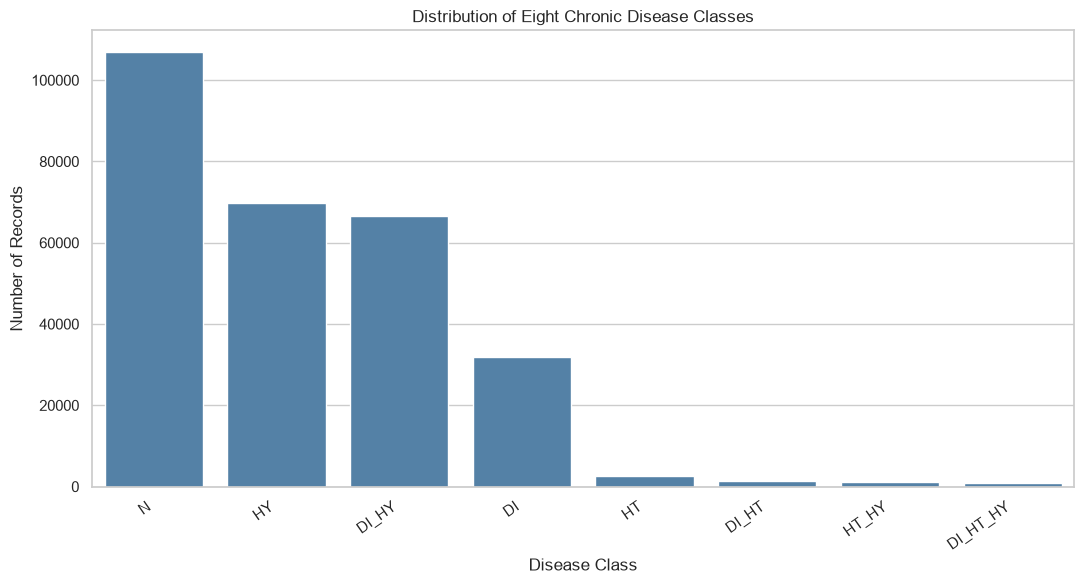

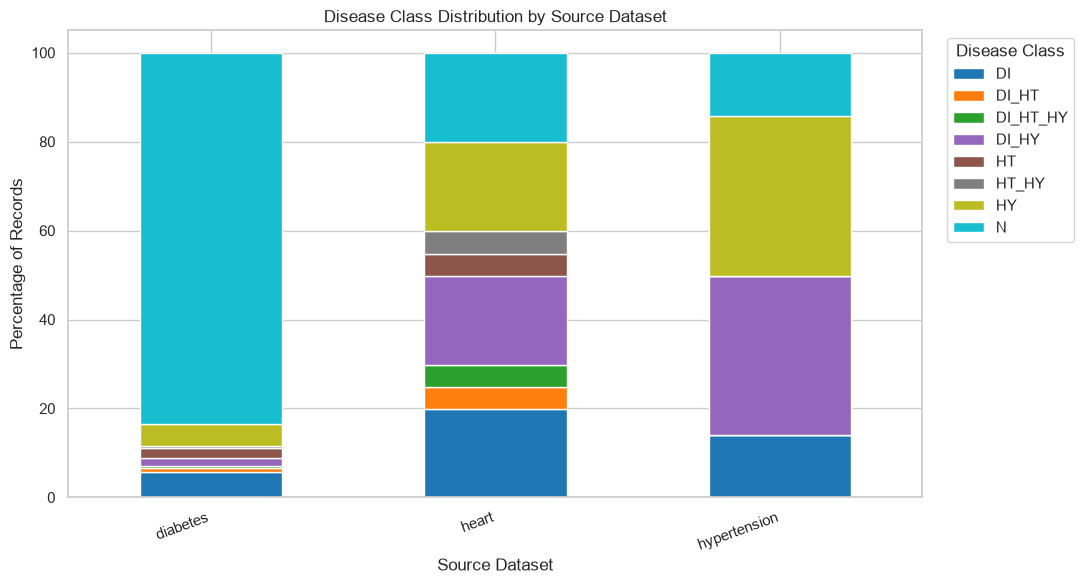

Step 9: Two figures saved.


In [10]:
# STEP 9: Disease Class Visualizations

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Figure 1: Disease class counts
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=class_table,
    x="Class",
    y="Count",
    color="steelblue"
)

plt.title("Distribution of Eight Chronic Disease Classes")
plt.xlabel("Disease Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig(
    figures_dir / "01_disease_class_counts.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Figure 2: Class distribution by source dataset
source_class_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    colormap="tab10"
)

plt.title("Disease Class Distribution by Source Dataset")
plt.xlabel("Source Dataset")
plt.ylabel("Percentage of Records")
plt.legend(
    title="Disease Class",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(
    figures_dir / "02_disease_classes_by_source.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Step 9: Two figures saved.")

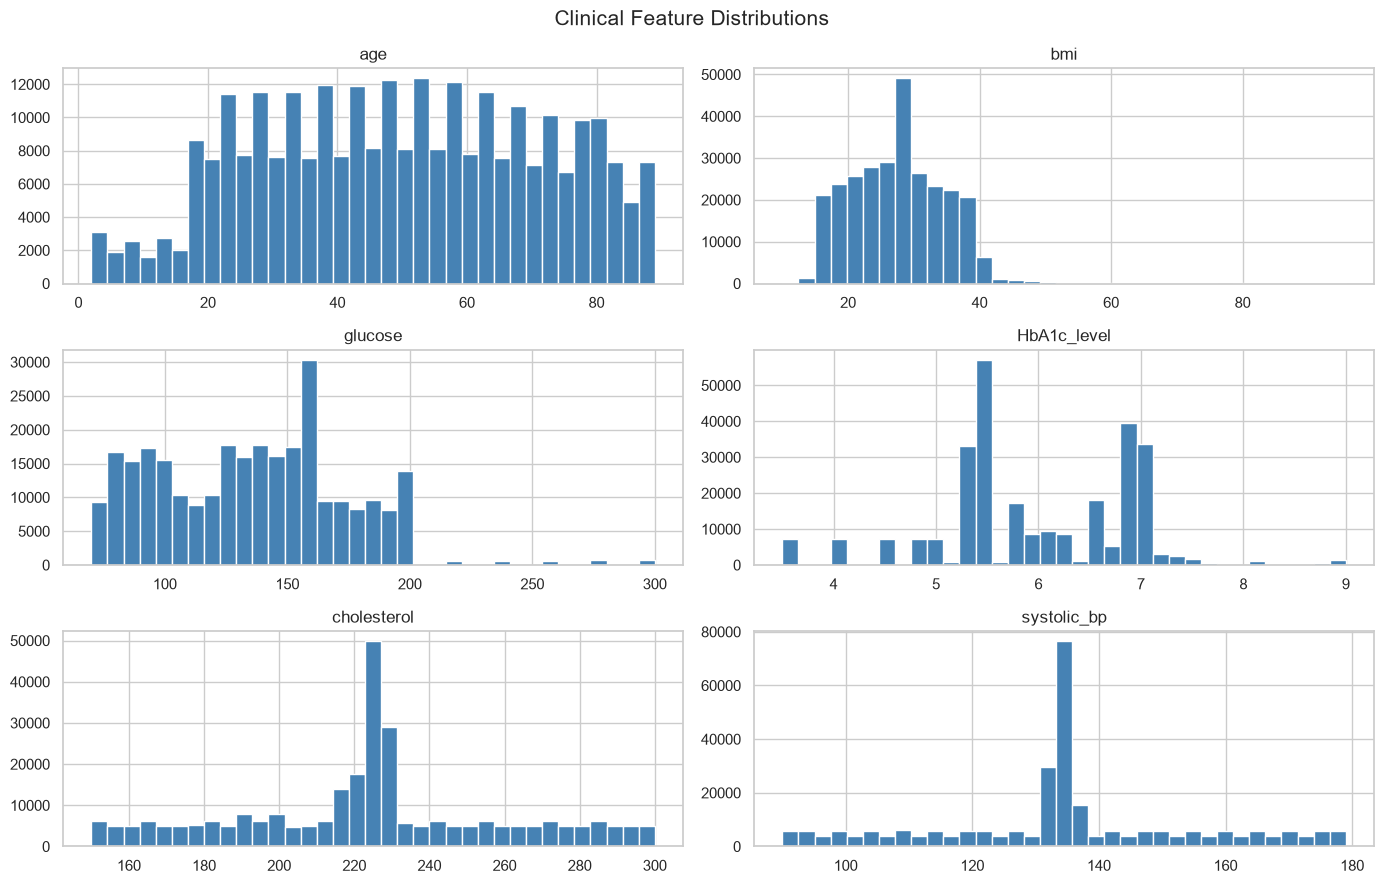

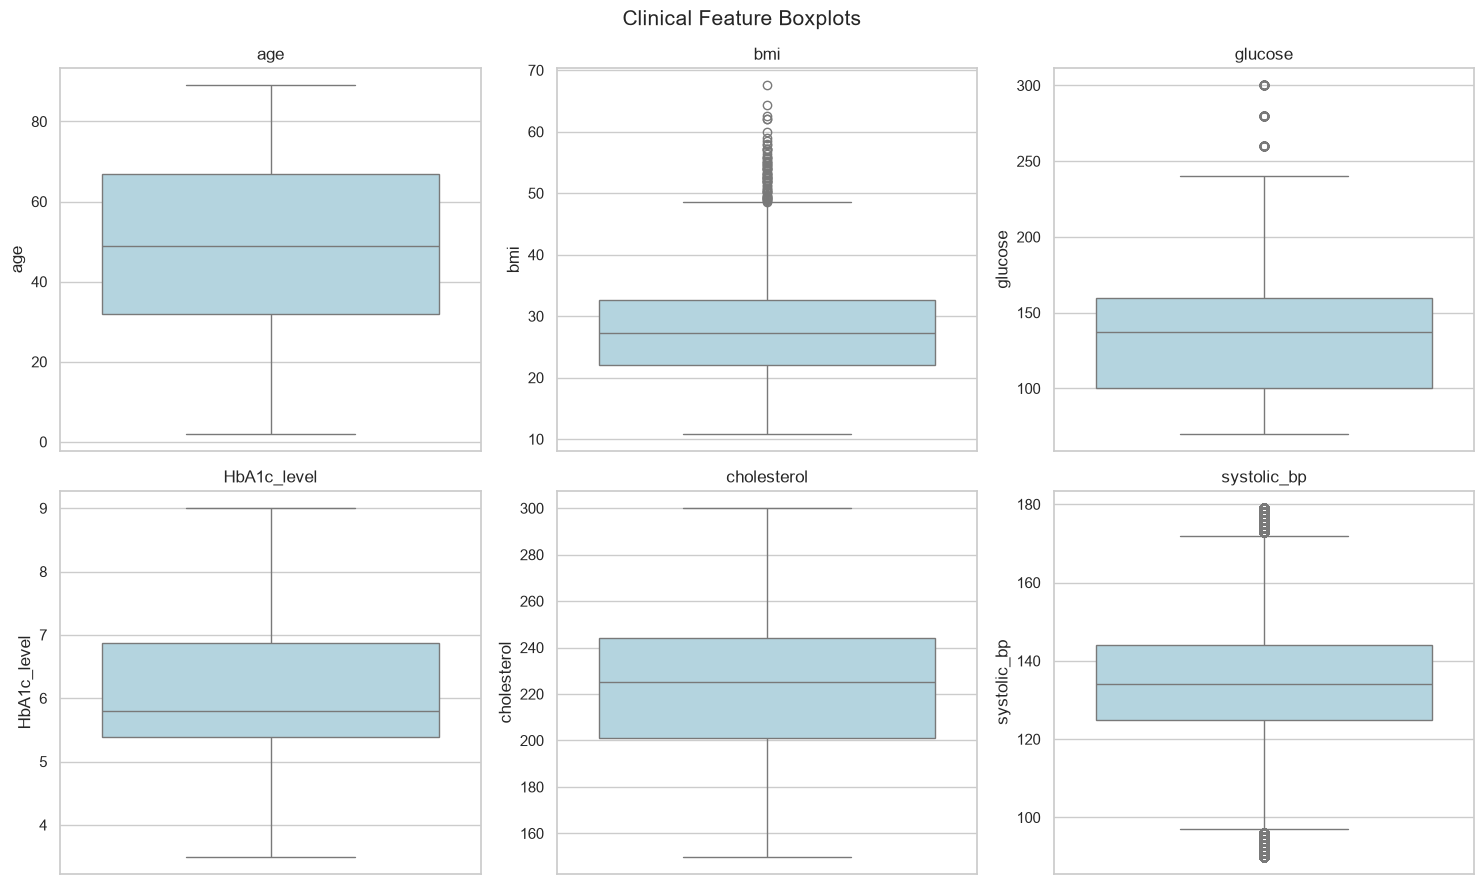

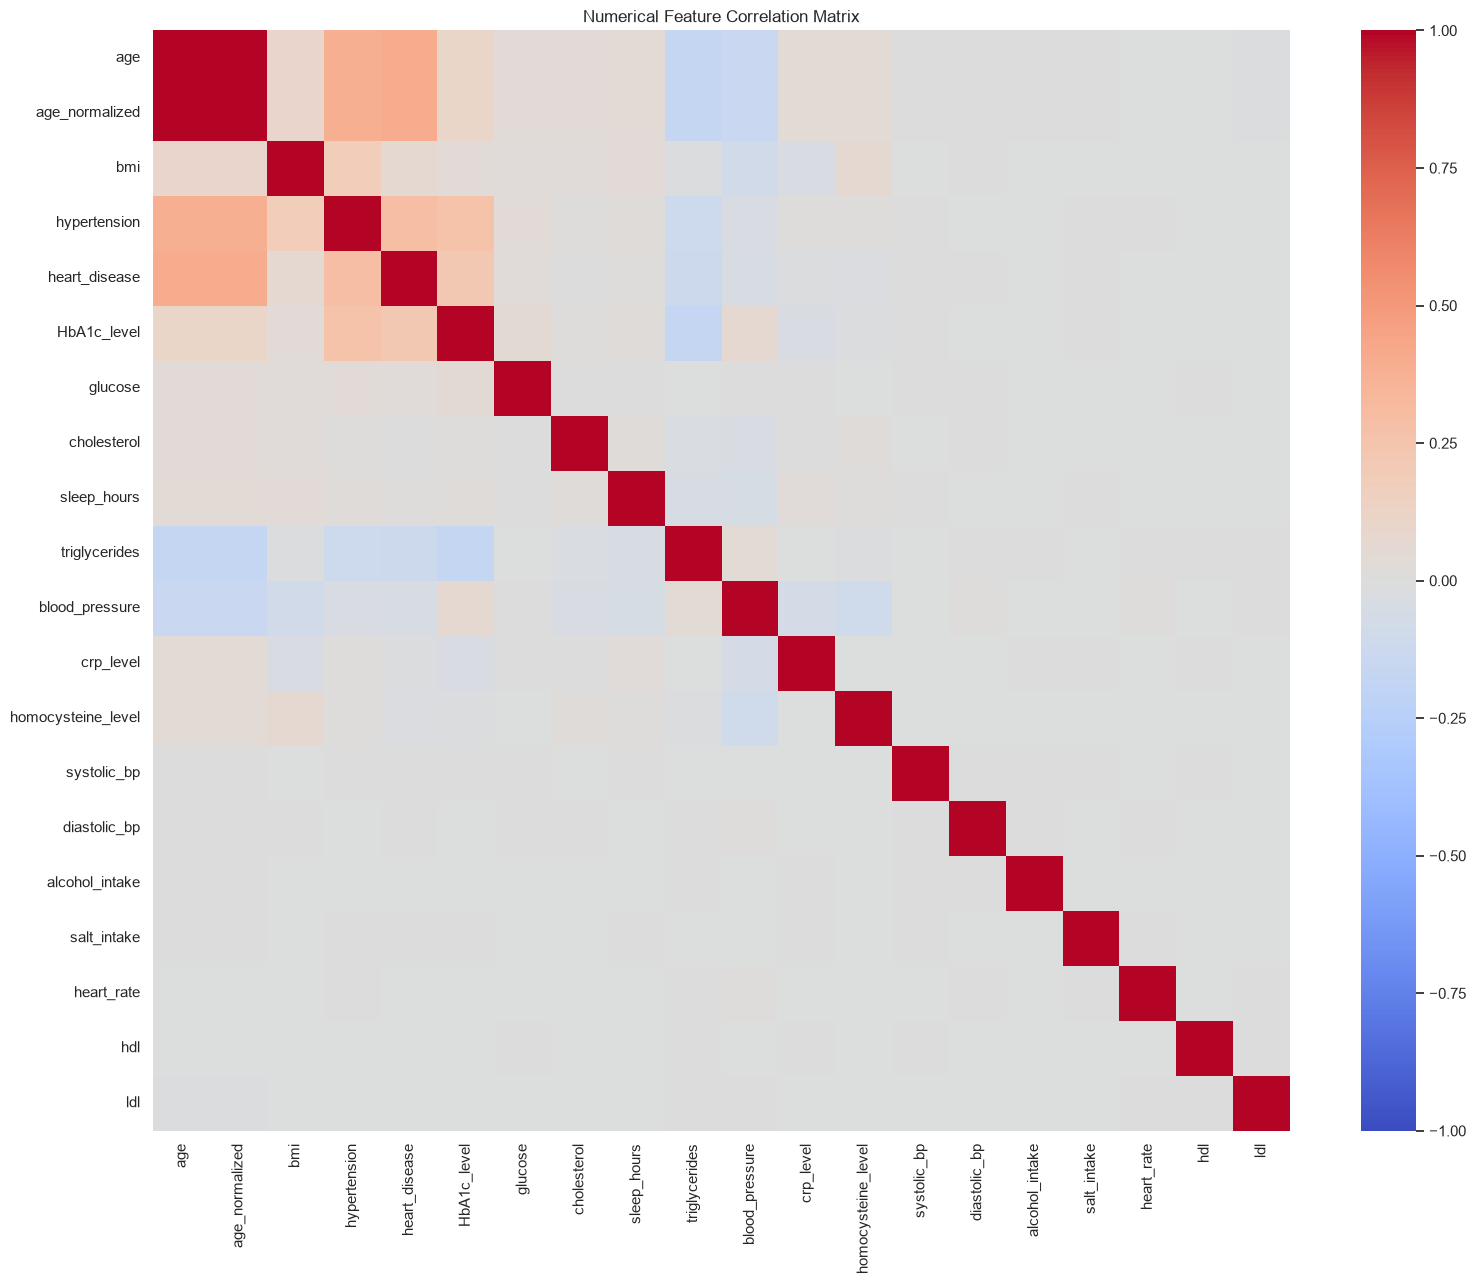

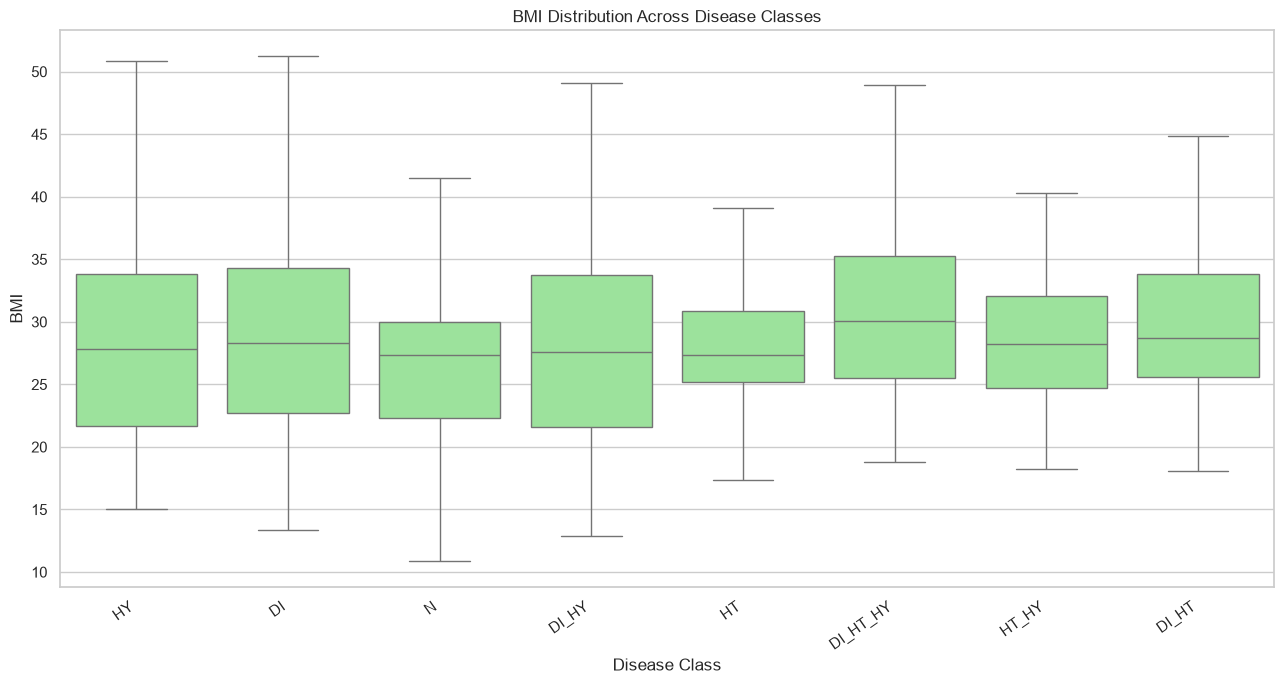

Step 10 completed.
Total figures: 6


In [11]:
# STEP 10: Clinical Distributions and Correlations

plot_features = [
    col for col in [
        "age", "bmi", "glucose",
        "HbA1c_level", "cholesterol",
        "systolic_bp"
    ]
    if col in df.columns
]

# Figure 3: Histograms
df[plot_features].hist(
    bins=35,
    figsize=(14, 9),
    color="steelblue",
    edgecolor="white"
)

plt.suptitle("Clinical Feature Distributions", fontsize=15)
plt.tight_layout()

plt.savefig(
    figures_dir / "03_clinical_histograms.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# Figure 4: Boxplots
# Sampling is used only to improve plotting performance.
plot_sample = df.sample(
    n=min(20000, len(df)),
    random_state=42
)

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9)
)

for ax, col in zip(axes.flat, plot_features):
    sns.boxplot(
        y=plot_sample[col],
        ax=ax,
        color="lightblue"
    )
    ax.set_title(col)

for ax in axes.flat[len(plot_features):]:
    ax.set_visible(False)

fig.suptitle("Clinical Feature Boxplots", fontsize=15)
plt.tight_layout()

plt.savefig(
    figures_dir / "04_clinical_boxplots.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# Figure 5: Correlation heatmap
correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(16, 13))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Numerical Feature Correlation Matrix")
plt.tight_layout()

plt.savefig(
    figures_dir / "05_correlation_heatmap.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

correlation_matrix.to_csv(
    tables_dir / "correlation_matrix.csv"
)


# Figure 6: BMI distribution across disease classes
plt.figure(figsize=(13, 7))

sns.boxplot(
    data=plot_sample,
    x="sublabel",
    y="bmi",
    color="lightgreen",
    showfliers=False
)

plt.title("BMI Distribution Across Disease Classes")
plt.xlabel("Disease Class")
plt.ylabel("BMI")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig(
    figures_dir / "06_bmi_by_disease_class.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Step 10 completed.")
print("Total figures:", len(list(figures_dir.glob("*.png"))))

In [12]:
# STEP 11: Create the Member 1 Data Dictionary

import pandas as pd

# Initial definitions based on column names and dataset context.
# Exact units, thresholds and coding must be verified
# against the original publisher's documentation.

descriptions = {
    "composite_key": "Composite category key; not a unique patient ID",
    "age_level": "Age group category",
    "gender": "Gender category",
    "bmi_level": "BMI category",
    "smoking": "Smoking status",
    "diabetes": "Diabetes status indicator",
    "age": "Age value",
    "age_normalized": "Normalized age representation",
    "bmi": "Body mass index",
    "hypertension": "Hypertension-related numerical field",
    "heart_disease": "Heart-disease-related numerical field",
    "HbA1c_level": "HbA1c measurement",
    "glucose": "Blood glucose measurement",
    "cholesterol": "Cholesterol measurement",
    "sleep_hours": "Sleep duration",
    "triglycerides": "Triglyceride measurement",
    "physical_activity": "Physical activity category",
    "family_history": "Family history indicator",
    "stress_level": "Stress category",
    "low_hdl_cholesterol": "Low HDL cholesterol indicator",
    "high_ldl_cholesterol": "High LDL cholesterol indicator",
    "blood_pressure": "Blood-pressure-related measurement",
    "high_blood_pressure": "High blood pressure indicator",
    "sugar_consumption": "Sugar consumption category",
    "crp_level": "C-reactive protein-related measurement",
    "homocysteine_level": "Homocysteine measurement",
    "systolic_bp": "Systolic blood pressure",
    "diastolic_bp": "Diastolic blood pressure",
    "alcohol_intake": "Alcohol intake measurement or score",
    "salt_intake": "Salt intake measurement or score",
    "heart_rate": "Heart rate",
    "hdl": "HDL cholesterol measurement",
    "ldl": "LDL cholesterol measurement",
    "education_level": "Education category",
    "employment_status": "Employment category",
    "source_dataset": "Original dataset source",
    "disease_flags": "Combined disease status indicators",
    "sublabel": "Eight-class disease-combination target",
    "label": "Binary Normal/Abnormal label"
}

review_columns = {
    "composite_key",
    "source_dataset",
    "disease_flags",
    "label",
    "diabetes",
    "hypertension",
    "heart_disease"
}

dictionary_rows = []

for col in df.columns:

    if col == "sublabel":
        role = "Target"

    elif col in review_columns:
        role = "Potential leakage / source proxy"

    else:
        role = "Candidate predictor"

    examples = (
        df[col]
        .dropna()
        .astype(str)
        .drop_duplicates()
        .head(3)
        .tolist()
    )

    dictionary_rows.append({
        "Column": col,
        "Data_Type": str(df[col].dtype),
        "Description": descriptions[col],
        "Units": "Not yet verified",
        "Role": role,
        "Unique_Values": int(df[col].nunique(dropna=False)),
        "Missing_Count": int(df[col].isna().sum()),
        "Example_Values": " | ".join(examples),
        "Verification_Status": "Needs publisher documentation review"
    })

data_dictionary = pd.DataFrame(dictionary_rows)

assert len(data_dictionary) == 39
assert set(data_dictionary["Column"]) == set(df.columns)

data_dictionary.to_csv(
    tables_dir / "data_dictionary.csv",
    index=False,
    encoding="utf-8-sig"
)

display(data_dictionary)

print("SUCCESS: Data dictionary generated.")
print("Total documented columns:", len(data_dictionary))

,Column,Data_Type,Description,Units,Role,Unique_Values,Missing_Count,Example_Values,Verification_Status
0,composite_key,str,Composite category key; not a unique patient ID,Not yet verified,Potential leakage / source proxy,192,0,Young_Female_Normal_Never_No | Young_Female_Ob...,Needs publisher documentation review
1,age_level,str,Age group category,Not yet verified,Candidate predictor,4,0,Young | Middle | Mature,Needs publisher documentation review
2,gender,str,Gender category,Not yet verified,Candidate predictor,2,0,Female | Male,Needs publisher documentation review
3,bmi_level,str,BMI category,Not yet verified,Candidate predictor,4,0,Normal | Obese | Overweight,Needs publisher documentation review
4,smoking,str,Smoking status,Not yet verified,Candidate predictor,3,0,Never | Current | Former,Needs publisher documentation review
5,diabetes,str,Diabetes status indicator,Not yet verified,Potential leakage / source proxy,2,0,No | Yes,Needs publisher documentation review
6,age,int64,Age value,Not yet verified,Candidate predictor,88,0,9 | 3 | 4,Needs publisher documentation review
7,age_normalized,float64,Normalized age representation,Not yet verified,Candidate predictor,151,0,0.0804597701149425 | 0.0114942528735632 | 0.02...,Needs publisher documentation review
8,bmi,float64,Body mass index,Not yet verified,Candidate predictor,14122,0,19.2 | 22.55 | 22.89,Needs publisher documentation review
9,hypertension,float64,Hypertension-related numerical field,Not yet verified,Potential leakage / source proxy,137,0,0.0 | 1.0 | 0.08300395256917,Needs publisher documentation review


SUCCESS: Data dictionary generated.
Total documented columns: 39


In [13]:
# STEP 12: Generate Dataset Quality Report and Handoff

from datetime import date
import hashlib

# 1. Calculate dataset checksum
sha256 = hashlib.sha256()

with csv_path.open("rb") as file:
    for chunk in iter(
        lambda: file.read(4 * 1024 * 1024),
        b""
    ):
        sha256.update(chunk)

dataset_hash = sha256.hexdigest()

# 2. Collect verified measurements
rows, columns = df.shape

missing_total = int(df.isna().sum().sum())
duplicates = int(df.duplicated().sum())
unique_keys = int(df["composite_key"].nunique())

hypertension_invalid = int(
    (~df["hypertension"].isin([0, 1])).sum()
)

heart_invalid = int(
    (~df["heart_disease"].isin([0, 1])).sum()
)

counts = df["sublabel"].value_counts()

# 3. Dataset source record
source_report = f"""# Dataset Source Record

## Dataset Identification

- Name: Multi-Class Chronic Disease Data Warehouse
- Publisher: Mendeley Data
- Version: 2
- DOI: 10.17632/6vnkkf5hv3.2
- URL: https://data.mendeley.com/datasets/6vnkkf5hv3/2
- Reported licence: CC BY 4.0
- Inspection date: {date.today()}
- Original file: {csv_path.name}
- SHA256: {dataset_hash}

## Verified Dataset Structure

- Records: {rows:,}
- Actual CSV columns: {columns}
- Target: sublabel
- Classes: {df["sublabel"].nunique()}

## Provenance

The group's CSV was previously verified to have the
same SHA256 hash as the CSV inside the downloaded
Mendeley Data ZIP.

The source ZIP also contains Dataset_Description .docx.

## Outstanding Documentation Review

Verify exact feature units, category coding,
and column meanings against the publisher DOCX.

The raw CSV has not been changed by Member 1.
"""

(tables_dir / "dataset_source.md").write_text(
    source_report,
    encoding="utf-8"
)

# 4. Data quality report
quality_report = f"""# EC5203 Group 07 — Data Quality Report

## 1. Dataset Overview

- Total records: {rows:,}
- Total columns: {columns}
- Target: sublabel
- Classes: {df["sublabel"].nunique()}

## 2. Missing Values

- Total pandas-detected missing cells: {missing_total:,}

No native null values were detected.
Placeholder values remain a separate concern.

## 3. Exact Duplicate Rows

- Duplicate rows: {duplicates:,}
- Duplicate percentage: {duplicates / rows * 100:.2f}%

Recommendation:
Investigate duplicates before deciding whether
they represent redundant or legitimate observations.

## 4. Composite Key

- Unique composite keys: {unique_keys}
- Repeated keys: {df["composite_key"].duplicated().sum():,}

The composite key is not a unique patient identifier.

## 5. Class Distribution

{counts.to_string()}

Largest class: {counts.idxmax()}
Smallest class: {counts.idxmin()}

The dataset contains substantial class imbalance.

## 6. Suspicious Numerical Indicators

- hypertension values outside 0/1: {hypertension_invalid:,}
- heart_disease values outside 0/1: {heart_invalid:,}

These are observed coding inconsistencies relative to
a binary interpretation. Their exact meanings require
verification against the source documentation.

Do not automatically convert these values to binary.

## 7. Target Leakage

The cross-tabulation shows that:

- label is determined by sublabel.
- disease_flags maps directly to disease combinations.

These must not be used as predictors.

Additional review is required for:
- diabetes
- hypertension
- heart_disease
- composite_key
- source_dataset

## 8. Source Dataset Effects

The source-class chart shows different class
distributions across the original source datasets.

Investigate whether models could identify the
source instead of learning disease patterns.

## 9. Visualization Findings

- Strong disease-class imbalance is visible.
- Clinical measurements show varying distributions.
- Some measurements have sharp distribution peaks.
- Potential outliers appear in several boxplots.
- Numerical correlations are present.
- BMI distributions overlap between disease classes.

The boxplots use a 20,000-record random sample.
Rare classes may be underrepresented in that sample.

## 10. Recommended Cleaning Decisions

For team review:

1. Verify publisher definitions and clinical units.
2. Investigate exact duplicate rows.
3. Check placeholder and unrealistic values.
4. Investigate fractional disease indicators.
5. Exclude confirmed target-derived predictors.
6. Investigate source-dataset artifacts.
7. Review identifiers before choosing a data split.
8. Fit preprocessing only on training data.

## 11. Member 1 Responsibility

This report documents observations and recommendations.

No cleaning, encoding, scaling, feature engineering,
or model training was performed.
"""

(tables_dir / "data_quality_report.md").write_text(
    quality_report,
    encoding="utf-8"
)

# 5. Handoff
handoff_report = """# EC5203 — Member 1 Handoff

## Completed

- Dataset acquisition and file verification
- Dataset dimensions and schema inspection
- Eight-class target identification
- Missing-value and duplicate audit
- Numerical and categorical quality inspection
- Target-leakage investigation
- Source-dataset comparison
- Statistical summary tables
- Six EDA visualizations
- Initial 39-column data dictionary
- Data-quality documentation

## Handoff to Member 2

Review the data-quality report before preprocessing.

Important issues:
- Exact duplicates
- Suspicious fractional indicators
- Potential target leakage
- Source-specific differences
- Verification of feature units and meanings

Member 2 owns the cleaning and preprocessing pipeline.

## Handoff to Members 3 and 4

- Target: sublabel
- Eight disease classes
- Significant class imbalance
- Confirmed target-derived columns: label, disease_flags
- Other disease indicators require leakage review
- Source and repeated-record structure require review

The modelling team must agree on the data split,
cross-validation and evaluation methodology.

## Outstanding

Verify the data dictionary against the publisher DOCX
and obtain team approval for cleaning recommendations.
"""

(tables_dir / "member1_handoff.md").write_text(
    handoff_report,
    encoding="utf-8"
)

print("SUCCESS: Reports generated.")

for name in [
    "dataset_source.md",
    "data_quality_report.md",
    "member1_handoff.md"
]:
    print(name)

SUCCESS: Reports generated.
dataset_source.md
data_quality_report.md
member1_handoff.md


In [14]:
# STEP 13: Verify Member 1 Deliverables

required_figures = [
    "01_disease_class_counts.png",
    "02_disease_classes_by_source.png",
    "03_clinical_histograms.png",
    "04_clinical_boxplots.png",
    "05_correlation_heatmap.png",
    "06_bmi_by_disease_class.png"
]

required_tables = [
    "dataset_summary.csv",
    "numerical_quality_audit.csv",
    "categorical_summary.csv",
    "class_counts.csv",
    "source_class_counts.csv",
    "source_class_percentages.csv",
    "source_statistics.csv",
    "missing_values.csv",
    "correlation_matrix.csv",
    "data_dictionary.csv",
    "dataset_source.md",
    "data_quality_report.md",
    "member1_handoff.md"
]

missing_files = []

for filename in required_figures:
    if not (figures_dir / filename).is_file():
        missing_files.append(filename)

for filename in required_tables:
    if not (tables_dir / filename).is_file():
        missing_files.append(filename)

assert df.shape == (280985, 39)
assert len(data_dictionary) == 39

# Confirm original CSV has not changed
assert dataset_hash == (
    "f7f7105f434ce7f179a6bd8d0ee0d1fea72ccd038af533deddc38c52fad143de"
), "Dataset hash changed!"

if missing_files:
    print("MISSING OUTPUT FILES:")
    for filename in missing_files:
        print(filename)
else:
    print("PASS: Member 1 deliverables generated.")
    print("Dataset integrity verified by SHA256.")
    print("Figures:", len(required_figures))
    print("Tables and reports:", len(required_tables))
    print("Original dataset unchanged.")

PASS: Member 1 deliverables generated.
Dataset integrity verified by SHA256.
Figures: 6
Tables and reports: 13
Original dataset unchanged.
